# Membrane equation and temperature dissipation equation
## Общий пространственный оператор и обучение эволюции двумерных полей


Цель — обучить модели, которые по начальному пространственному полю и физическому коэффициенту
рассчитывают решение PDE в последующие моменты времени. Рассматриваются малые колебания
закреплённой мембраны и теплопроводность. Статическая аналогия с электростатикой проверяется отдельно.


## 0. Запуск и воспроизводимость

1. Сохранить пять модулей рядом с этим ноутбуком.
2. Установить зависимости в окружение ядра:
   ```bash
   python -m pip install numpy scipy scikit-learn h5py requests fsspec aiohttp networkx sympy matplotlib pytest
   ```
3. Выполнить разделы 0–4: графы уравнений, статическая аналогия, аналитические проверки.
4. В разделе 5 включить просмотр каталога ZIP и выбрать **2D** файлы train/valid/test.
   Выбор не следует делать только по слову Heat: архив содержит и одномерные задачи.
5. Включить загрузку, затем `RUN_EXTERNAL = True` и выполнить разделы 6–11.
   Для повторного эксперимента использовать уже загруженные файлы.

Для нескольких запусков фиксируются seed, параметры модели, версии библиотек и SHA-256 модулей.
По умолчанию многогигабайтная загрузка и обучение выключены. Это настройка выполнения,
а не утверждение о завершённой работе.


In [1]:
from pathlib import Path
import importlib.metadata as metadata
import json
import platform
import sys
import time
import subprocess

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from IPython.display import display, Markdown
from scipy.sparse.linalg import spsolve

ROOT = Path.cwd()
required = ['data.py', 'physics.py', 'model.py', 'equations.py', 'test_lab.py']
missing = [name for name in required if not (ROOT / name).is_file()]
if missing:
    raise FileNotFoundError(
        'Сохраните рядом с ноутбуком модули из предыдущего сообщения: '
        + ', '.join(missing)
    )
sys.path.insert(0, str(ROOT))

from data import (
    Grid, Fields, WAVE_URL, MAE_URL, download, download_zip_member,
    zip_members, h5_inventory, load_wave, load_heat, split_indices, fingerprint,
)
from physics import laplacian, evolve, identify, audit, metrics, time_step
from model import PODOperator
from equations import symbolic_equations, graph_representations

RAW = ROOT / 'data' / 'raw'
RESULTS = ROOT / 'results'
RAW.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 115, 'font.size': 10, 'font.family': 'DejaVu Sans'})
packages = ['numpy', 'scipy', 'scikit-learn', 'h5py', 'requests',
            'fsspec', 'aiohttp', 'networkx', 'sympy', 'matplotlib', 'pytest']
environment = {
    'python': sys.version, 'platform': platform.platform(), 'seed': SEED,
    'packages': {name: metadata.version(name) for name in packages},
    'modules_sha256': {name: fingerprint(ROOT / name) for name in required},
}
(RESULTS / 'environment.json').write_text(
    json.dumps(environment, ensure_ascii=False, indent=2), encoding='utf-8'
)
print('Окружение и контрольные суммы модулей сохранены.')


Окружение и контрольные суммы модулей сохранены.


## 1. Физическая и математическая постановка

Пусть $\Delta=\partial_{xx}+\partial_{yy}$. Температуру обозначаем $T$; это **отклонение**
от постоянной температуры окружения, поэтому отрицательные значения допустимы.

| Задача | Базовая модель | Расширение для отдельной проверки |
|---|---|---|
| Мембрана | $u_{tt}=c^2\Delta u$ | $u_{tt}+\gamma u_t=c^2\Delta u$ |
| Теплопроводность | $T_t=\alpha\Delta T$ | $T_t=\alpha\Delta T-\beta T$ |

$u$ — малый поперечный прогиб; $c^2=S/\rho_s$ для постоянного натяжения $S$ и поверхностной
плотности $\rho_s$. Параметры $S$ и $\rho_s$ независимо из такой задачи не восстанавливаются.
$\alpha=k/(\rho c_p)$ — температуропроводность. $\gamma\geq0$ — затухание, $\beta\geq0$ —
линейная объёмная теплоотдача в приближении тонкого слоя. Последние два члена **отсутствуют**
в выбранных базовых HTTP-данных.

Общий пространственный оператор $\mathcal A=-\Delta$ позволяет записать
$u_{tt}+\gamma u_t+c^2\mathcal A u=0$ и $T_t+\alpha\mathcal A T+\beta T=0$.
Одинаковый пространственный оператор не означает одинаковую временную эволюцию.

### Начальные и граничные условия

* Мембрана: круг радиуса 1 с центром $(0.5,0.5)$, $u|_{\partial\Omega}=0$.
  Непрерывная задача требует $u(0)$ и $u_t(0)$. Реализация получает **два первых кадра**
  $u(t_0),u(t_1)$; оценка точности начинается с $t_2$. Не утверждаем, что неизвестная
  начальная скорость равна нулю.
* Теплопроводность MAE-PDEs: квадрат $[-1,1]^2$ с периодическими границами, начальное поле $T(0)$.
  Оценка начинается с $t_1$. При $\beta=0$ средняя температура сохраняется; сглаживаются
  неоднородности. Это не эксперимент с охлаждением через внешнюю границу.

Физические параметры: $\theta_m=(c,\gamma)$, $\theta_T=(\alpha,\beta)$.
В коде `d=c**2` для мембраны и `d=alpha` для теплопроводности; `loss` — $\gamma$ либо $\beta$.
Ожидается $c=2$, $\gamma=0$; в MAE-PDEs $\alpha\in[0.002,0.02]$, $\beta=0$.
Единицы и время сохраняются как в источниках; произвольного перевода в СИ нет.


In [2]:
for name, equation in symbolic_equations().items():
    display(Markdown('**' + name + '**'))
    display(equation)


**heat_base**

Eq(Derivative(T(x, y, t), t), alpha*(Derivative(T(x, y, t), (x, 2)) + Derivative(T(x, y, t), (y, 2))))

**heat_modified**

Eq(Derivative(T(x, y, t), t), alpha*(Derivative(T(x, y, t), (x, 2)) + Derivative(T(x, y, t), (y, 2))) - beta*T(x, y, t))

**wave_base**

Eq(Derivative(u(x, y, t), (t, 2)), c**2*(Derivative(u(x, y, t), (x, 2)) + Derivative(u(x, y, t), (y, 2))))

**wave_modified**

Eq(Derivative(u(x, y, t), (t, 2)), c**2*(Derivative(u(x, y, t), (x, 2)) + Derivative(u(x, y, t), (y, 2))) - gamma*Derivative(u(x, y, t), t))

## 2. Вычислительный граф уравнения

Строим DAG правой части PDE. Общие операции: вторые пространственные производные,
суммирование, умножение на коэффициент. У мембраны дополнительно $u_t=v$.
Временной интегратор не включён в DAG; обратная связь между шагами относится к солверу.
Граф выражения и граф нейронной сети — разные понятия; здесь показан именно граф уравнения.

Ниже выводятся изображения, порядок узлов, словарь и матрица смежности:
$A_{ij}=1$, если результат узла $i$ передаётся в узел $j$.


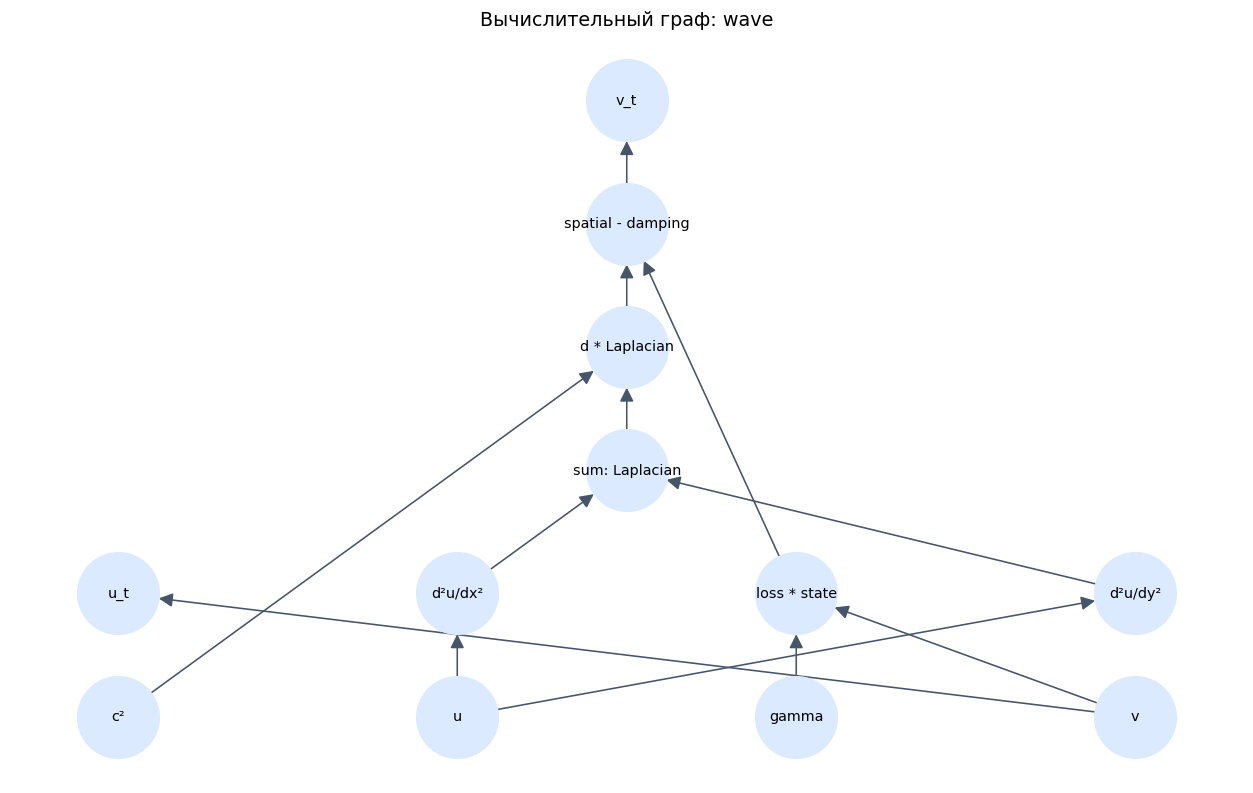

Порядок узлов: ['field', 'd', 'loss', 'velocity', 'dxx', 'dyy', 'damping', 'u_rate', 'laplace', 'spatial', 'rhs', 'rate']


array([[0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

{'field': {'label': 'u', 'children': ['dxx', 'dyy']},
 'd': {'label': 'c²', 'children': ['spatial']},
 'loss': {'label': 'gamma', 'children': ['damping']},
 'velocity': {'label': 'v', 'children': ['damping', 'u_rate']},
 'dxx': {'label': 'd²u/dx²', 'children': ['laplace']},
 'dyy': {'label': 'd²u/dy²', 'children': ['laplace']},
 'damping': {'label': 'loss * state', 'children': ['rhs']},
 'u_rate': {'label': 'u_t', 'children': []},
 'laplace': {'label': 'sum: Laplacian', 'children': ['spatial']},
 'spatial': {'label': 'd * Laplacian', 'children': ['rhs']},
 'rhs': {'label': 'spatial - damping', 'children': ['rate']},
 'rate': {'label': 'v_t', 'children': []}}

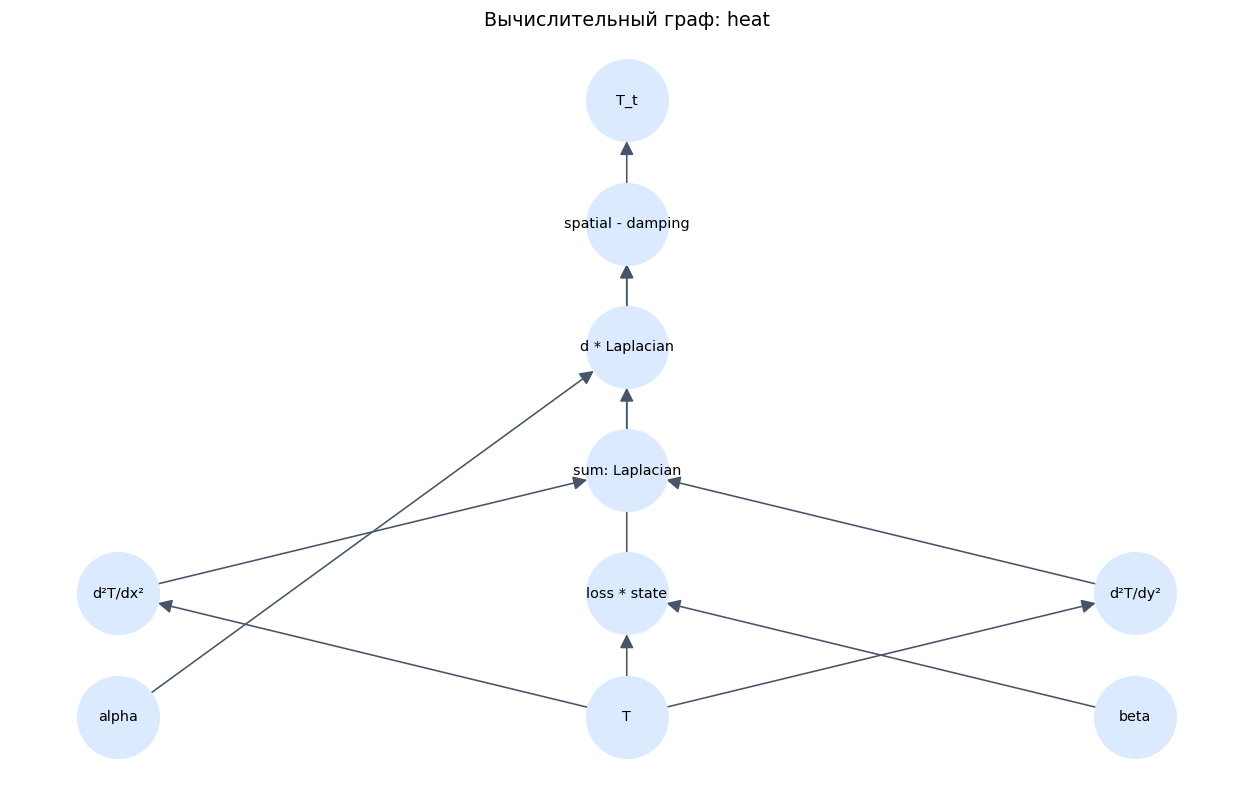

Порядок узлов: ['field', 'd', 'loss', 'dxx', 'dyy', 'damping', 'laplace', 'spatial', 'rhs', 'rate']


array([[0, 0, 0, 1, 1, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])

{'field': {'label': 'T', 'children': ['dxx', 'dyy', 'damping']},
 'd': {'label': 'alpha', 'children': ['spatial']},
 'loss': {'label': 'beta', 'children': ['damping']},
 'dxx': {'label': 'd²T/dx²', 'children': ['laplace']},
 'dyy': {'label': 'd²T/dy²', 'children': ['laplace']},
 'damping': {'label': 'loss * state', 'children': ['rhs']},
 'laplace': {'label': 'sum: Laplacian', 'children': ['spatial']},
 'spatial': {'label': 'd * Laplacian', 'children': ['rhs']},
 'rhs': {'label': 'spatial - damping', 'children': ['rate']},
 'rate': {'label': 'T_t', 'children': []}}

In [3]:
for kind in ('wave', 'heat'):
    representation = graph_representations(kind)
    graph = representation['graph']
    for level, generation in enumerate(nx.topological_generations(graph)):
        for node in generation:
            graph.nodes[node]['level'] = level
    position = nx.multipartite_layout(graph, subset_key='level', align='horizontal')
    fig, ax = plt.subplots(figsize=(11, 7))
    nx.draw_networkx(
        graph, pos=position, labels=nx.get_node_attributes(graph, 'label'),
        node_color='#dbeafe', node_size=2600, font_size=9,
        edge_color='#475569', arrowsize=18, ax=ax,
    )
    ax.set_title('Вычислительный граф: ' + kind)
    ax.axis('off')
    fig.tight_layout()
    fig.savefig(RESULTS / (kind + '_equation_graph.png'), bbox_inches='tight')
    plt.show()
    print('Порядок узлов:', representation['nodes'])
    display(representation['adjacency'])
    display(representation['dictionary'])
    (RESULTS / (kind + '_graph.json')).write_text(json.dumps({
        'nodes': representation['nodes'],
        'adjacency': representation['adjacency'].tolist(),
        'dictionary': representation['dictionary'],
    }, ensure_ascii=False, indent=2), encoding='utf-8')


## 3. Аналогия Фейнмана: отдельный стационарный контроль

В главе II.12 «Электростатические аналогии» сравниваются стационарные задачи. При согласованных
области, коэффициентах, источниках и границах электростатика, равновесие мембраны и стационарная
теплопроводность приводятся к $-\nabla\cdot(a\nabla w)=f$.

Для однородных сред и нулевых условий Дирихле:
$-\varepsilon\Delta\varphi=\rho_e$, $-S\Delta u=p$, $-k\Delta T=Q$.
Выберем нормированные источники $\rho_e/\varepsilon=p/S=Q/k=f$.
Тогда нормированные поля совпадают по единственности задачи Пуассона.

**Собственный контрольный пример, не HTTP-данные:** единичный квадрат,
$w_*=\sin(\pi x)\sin(\pi y)$ и $f=2\pi^2w_*$.
Коэффициенты ниже условные, безразмерные. Три решения должны совпасть между собой,
но иметь ненулевую погрешность относительно непрерывного $w_*$ из-за сетки.
Динамические наборы данных имеют разные геометрии — совпадение их полей не предполагается.


Максимальное расхождение трёх полей: 1.554312234475219e-14
Относительная L2-ошибка относительно аналитического решения: 0.0005142004781573551


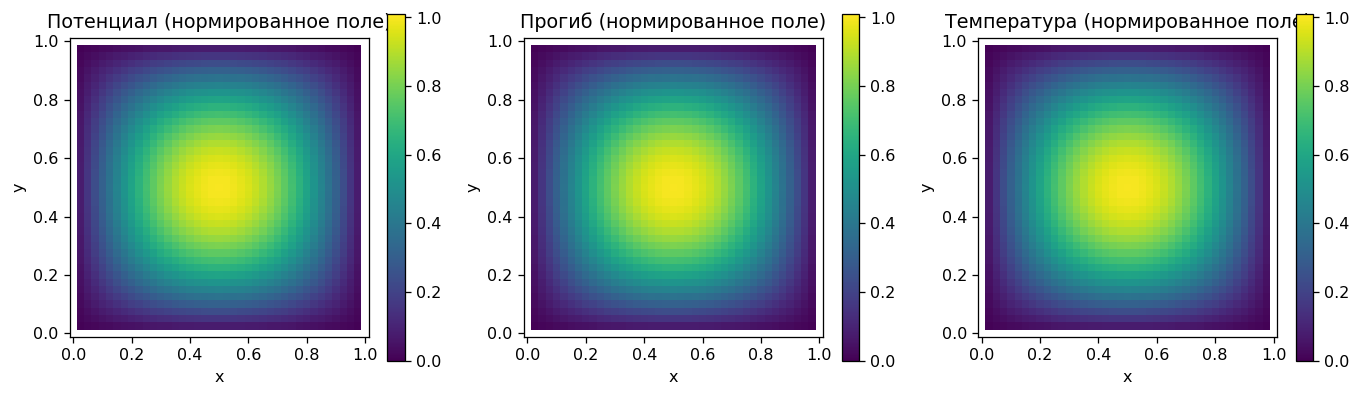

In [4]:
axis = np.linspace(0, 1, 41)
xx, yy = np.meshgrid(axis, axis)
mask = np.ones(xx.shape, dtype=bool)
mask[[0, -1], :] = False
mask[:, [0, -1]] = False
static_grid = Grid(axis, axis.copy(), mask)
static_laplace = laplacian(static_grid)
exact_static = (np.sin(np.pi * xx) * np.sin(np.pi * yy))[mask]
source = 2 * np.pi**2 * exact_static
static_solutions = []
for coefficient in (2.0, 3.0, 5.0):
    static_solutions.append(spsolve(-coefficient * static_laplace, coefficient * source))
print('Максимальное расхождение трёх полей:',
      max(np.max(np.abs(w - static_solutions[0])) for w in static_solutions))
print('Относительная L2-ошибка относительно аналитического решения:',
      np.linalg.norm(static_solutions[0] - exact_static) / np.linalg.norm(exact_static))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, field, title in zip(axes, static_solutions, ('Потенциал', 'Прогиб', 'Температура')):
    mesh = ax.pcolormesh(xx, yy, static_grid.image(field), shading='auto', vmin=0, vmax=1.01)
    ax.set(title=title + ' (нормированное поле)', xlabel='x', ylabel='y', aspect='equal')
    fig.colorbar(mesh, ax=ax)
fig.tight_layout()
plt.show()


## 4. Проверка численного метода до обучения

Пространственный оператор — пятиточечный лапласиан. Для теплопроводности применяется
схема Кранка–Николсон, для мембраны — центральная схема второго порядка с проверкой CFL.
Граница круга на регулярной сетке аппроксимируется ступенчато; это отдельный источник ошибки.

На единичном периодическом квадрате одна мода
$\psi=\sin(2\pi x)\sin(2\pi y)$ имеет $\lambda=8\pi^2$ для $-\Delta$:
$T=\psi e^{-\alpha\lambda t}$, $u=\psi\cos(c\sqrt{\lambda}t)$.
Сравниваем с **непрерывным** решением: таблица включает пространственную и временную ошибки.
Тесты в `test_lab.py` дополнительно проверяют дискретное собственное значение,
идентификацию параметров, графы, разделение выборки и обучение на новой комбинации мод.


In [5]:
test_run = subprocess.run(
    [sys.executable, '-m', 'pytest', '-q', str(ROOT / 'test_lab.py')],
    cwd=ROOT, capture_output=True, text=True,
)
print(test_run.stdout)
if test_run.returncode:
    print(test_run.stderr)
    raise RuntimeError('Исправьте тесты перед запуском эксперимента.')


.......                                                                  [100%]
7 passed in 1.83s



[{'n': 16, 'heat_L2': 0.0021564503740616513, 'wave_L2': 0.00920663062613945},
 {'n': 32, 'heat_L2': 0.0005405735532190008, 'wave_L2': 0.002302417949735235},
 {'n': 64, 'heat_L2': 0.00013521010562728315, 'wave_L2': 0.000572326678365192}]

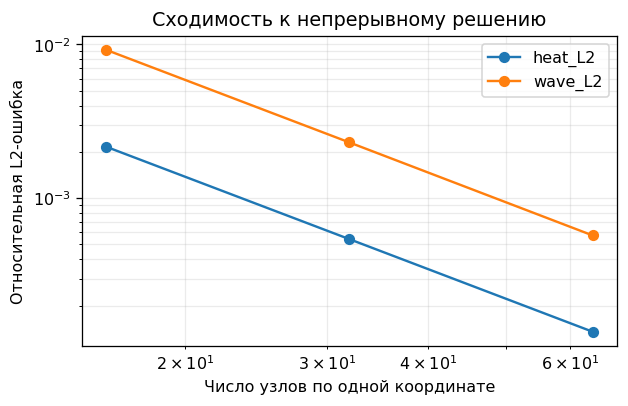

In [6]:
convergence = []
for n in (16, 32, 64):
    axis = np.arange(n) / n
    xx, yy = np.meshgrid(axis, axis)
    grid = Grid(axis, axis.copy(), np.ones((n, n), dtype=bool), True)
    operator = laplacian(grid)
    mode = (np.sin(2*np.pi*xx) * np.sin(2*np.pi*yy)).ravel()
    t_check = np.linspace(0, 0.2, 201)
    heat_exact = np.exp(-0.02 * 8*np.pi**2 * t_check[:, None]) * mode
    wave_exact = np.cos(np.sqrt(8)*np.pi * t_check[:, None]) * mode
    heat_numerical = evolve(operator, mode, t_check, 0.02, 'heat')
    wave_numerical = evolve(operator, wave_exact[:2], t_check, 1.0, 'wave')
    convergence.append({
        'n': n,
        'heat_L2': metrics(heat_exact, heat_numerical, start=1)['relative_l2'],
        'wave_L2': metrics(wave_exact, wave_numerical, start=2)['relative_l2'],
    })
display(convergence)
fig, ax = plt.subplots(figsize=(6, 3.5))
for name in ('heat_L2', 'wave_L2'):
    ax.loglog([r['n'] for r in convergence], [r[name] for r in convergence], 'o-', label=name)
ax.set(xlabel='Число узлов по одной координате', ylabel='Относительная L2-ошибка',
       title='Сходимость к непрерывному решению')
ax.legend()
ax.grid(True, which='both', alpha=0.25)
plt.show()


## 5. Два источника открытых данных и их загрузка

| Источник | Файл / часть | Что используем | Ограничение |
|---|---|---|---|
| RIGNO, Zenodo v2 | Wave-C-Sines.nc, около 2.1 GB | Поля волнового уравнения в круге, 21 кадр, $c=2$ | Коэффициент фиксирован, горизонт короткий |
| MAE-PDEs, Zenodo v1 | 2D Heat внутри mae_pdes_data.zip | $64\times64$, 100 кадров, $\alpha\in[0.002,0.02]$ | Полный архив около 38.9 GB; нужны только выбранные члены |

Это опубликованные **численные симуляции**, не экспериментальные измерения.
Два файла из одной коллекции не считались бы двумя независимыми источниками.
Загрузка по HTTPS удовлетворяет требованию HTTP-доступа. URL и SHA-256 сохраняет `data.py`.

**Проверка MAE-PDEs обязательна.** В просмотренной версии генератора `2D_combined.py`
порядок массивов коэффициентов и ветвей генерации выглядит несогласованным.
Нельзя считать название файла или нулевые метки адvection достаточным доказательством PDE.
Раздел 6 проверяет заявленный коэффициент по полям. Если проверка не проходит,
нужно исследовать файл и исправить адаптер/выбор данных; нельзя автоматически перемаркировать
набор, ослабить порог без обоснования или выдать его за чистую теплопроводность.

Извлечение ZIP через Range работает только при поддержке сервером.
При ошибке можно загрузить архив вручную по указанному URL и извлечь три выбранных файла;
местные имена должны совпасть с путями ниже. При этом сохраните происхождение файлов.


In [14]:
LIST_ARCHIVE = True
DOWNLOAD_HTTP = True
RUN_EXTERNAL = False

WAVE_PATH = RAW / 'Wave-C-Sines.nc'
HEAT_PATHS = {split: RAW / ('mae_2d_' + split + '.h5')
              for split in ('train', 'valid', 'test')}

# Скопируйте точные имена из zip_members(), не имена локальных файлов.
#MAE_MEMBERS = {'train': None, 'valid': None, 'test': None}
MAE_MEMBERS = {
    'train': '2D/train/Heat_4096.h5',
    'valid': '2D/valid/Heat_256.h5',
    'test':  '2D/test/Heat_256.h5'
}
if LIST_ARCHIVE:
    members = zip_members()
    display(members)

if DOWNLOAD_HTTP:
    if not WAVE_PATH.exists():
        download(WAVE_URL, WAVE_PATH)
    for split, path in HEAT_PATHS.items():
        if not path.exists():
            member = MAE_MEMBERS[split]
            if not member:
                raise ValueError('Укажите MAE_MEMBERS[' + repr(split) + '] по каталогу ZIP.')
            download_zip_member(member, path)

for path in (WAVE_PATH, *HEAT_PATHS.values()):
    print(path.name, 'готов' if path.is_file() else 'не загружен')
    if path.is_file():
        display(h5_inventory(path))


['1D/train/PDE_Combined_8000.h5',
 '1D/train/Heat_Combined_12288.h5',
 '1D/train/Wave_Combined_8192.h5',
 '1D/train/WaveNeu_4096.h5',
 '1D/train/WaveDir_4096.h5',
 '1D/train/KS_4096.h5',
 '1D/train/HeatDirichlet_4096.h5',
 '1D/train/KdVBurgers_4096.h5',
 '1D/train/Advection_4096.h5',
 '1D/train/HeatNeumann_4096.h5',
 '1D/train/Heat_4096.h5',
 '1D/train/Burgers_4096.h5',
 '1D/valid/Heat_256.h5',
 '1D/valid/Heat_Combined_768.h5',
 '1D/valid/PDE_Combined_1024.h5',
 '1D/valid/Wave_Combined_512.h5',
 '1D/valid/WaveNeu_256.h5',
 '1D/valid/WaveDir_256.h5',
 '1D/valid/HeatDirichlet_256.h5',
 '1D/valid/HeatNeumann_256.h5',
 '1D/valid/Advection_256.h5',
 '1D/valid/KdVBurgers_256.h5',
 '1D/valid/KS_256.h5',
 '1D/valid/Burgers_256.h5',
 '1D/pretrain/KdVBurgers_10000.h5',
 '2D/pretrain/HeatAdvBurgers_12288.h5',
 '2D/train/Heat_1024.h5',
 '2D/train/Burgers_1024.h5',
 '2D/train/Advection_1024.h5',
 '2D/train/NS_1000.h5',
 '2D/train/HeatAdvBurgers_3072.h5',
 '2D/valid/Advection_256.h5',
 '2D/valid/Hea

KeyError: "There is no item named '2D/train/Heat_4096.h5' in the archive"

## 6. Подготовка, аудит и протокол разделения

RIGNO: берём ограниченное число траекторий, интерполируем на сетку $40\times40$;
после маскирования остаются только узлы внутри круга и исходной триангуляции.
Численная граница будет несколько отличаться от исходной FEM-геометрии.
MAE-PDEs: сохраняем регулярную периодическую сетку источника.

Все пространственные узлы одной траектории принадлежат одному split. Для RIGNO —
фиксированное случайное разбиение 70/15/15; для MAE — опубликованные train/valid/test.
В минимальном эксперименте ограничиваем выборки; выводы относятся именно к выбранным поднаборам.
Число траекторий, узлов и временных кадров выводится из реально прочитанных массивов.

Невязка, вычисленная на грубой сетке, не равна ошибке модели и зависит от дискретизации.
Для Heat задаём предварительный диагностический порог медианы 0.20 и проверяем
восстановление коэффициента на нескольких траекториях. Порог не используется как метрика успеха ML.
Для мембраны показываем распределение невязки без жёсткого порога из-за интерполяции и границы.


In [ ]:
splits = {}
operators = {}
audit_summary = {}
WAVE_COUNT = 128
HEAT_COUNTS = {'train': 128, 'valid': 32, 'test': 32}
HEAT_MEDIAN_RESIDUAL_LIMIT = 0.20

if RUN_EXTERNAL:
    missing_data = [str(p) for p in (WAVE_PATH, *HEAT_PATHS.values()) if not p.is_file()]
    if missing_data:
        raise FileNotFoundError('Не загружены данные: ' + ', '.join(missing_data))
    wave = load_wave(WAVE_PATH, count=WAVE_COUNT, resolution=40)
    train_ids, valid_ids, test_ids = split_indices(len(wave.u), seed=SEED)
    splits['wave'] = dict(zip(('train', 'valid', 'test'),
                             (wave.subset(train_ids), wave.subset(valid_ids), wave.subset(test_ids))))
    splits['heat'] = {name: load_heat(HEAT_PATHS[name], group=name, count=HEAT_COUNTS[name])
                      for name in ('train', 'valid', 'test')}
    np.savez(RESULTS / 'wave_split_indices.npz', train=train_ids, valid=valid_ids, test=test_ids)

    for kind, parts in splits.items():
        operators[kind] = laplacian(parts['train'].grid)
        for name, dataset in parts.items():
            base = parts['train']
            if not (np.array_equal(dataset.grid.mask, base.grid.mask)
                    and np.allclose(dataset.grid.x, base.grid.x)
                    and np.allclose(dataset.grid.y, base.grid.y)):
                raise ValueError('Модель POD требует общей пространственной сетки внутри задачи.')
            print(kind, name, dataset.u.shape, 'time:', dataset.t[[0, -1]],
                  'd range:', dataset.d.min(), dataset.d.max())

        dataset = parts['train']
        residuals = audit(dataset, operators[kind])
        audit_summary[kind] = {'median': float(np.median(residuals)),
                               'p90': float(np.quantile(residuals, 0.9))}
        display({kind: audit_summary[kind]})
        fig, ax = plt.subplots(figsize=(6, 3))
        ax.hist(residuals, bins=20)
        ax.set(title=kind + ': невязка PDE до обучения', xlabel='Относительная невязка', ylabel='Траектории')
        plt.show()
        if kind == 'heat':
            recovered = []
            for i in range(min(8, len(dataset.u))):
                estimate = identify(dataset.u[i], dataset.t, operators[kind], kind)
                recovered.append(estimate['d'] / dataset.d[i])
            display({'alpha_fit / alpha_metadata': recovered})
            if (np.median(residuals) > HEAT_MEDIAN_RESIDUAL_LIMIT
                    or not 0.8 <= np.median(recovered) <= 1.2):
                raise ValueError('MAE-PDEs не прошёл проверку меток/сеток/PDE. Обучение остановлено.')
else:
    print('Внешние данные не обрабатывались. Включите RUN_EXTERNAL после загрузки.')


## 7. Обучаемая модель и выбор гиперпараметров

Строки матрицы снимков — пространственные поля **только train**. Метод POD/SVD строит
ортонормированный базис $V\in\mathbb R^{P\times r}$, $z=V^Tu$, $u\approx Vz$.
Затем обучается редуцированный оператор $A$:

$$\min_A \|Y-XA^T\|_F^2+\lambda\|A\|_F^2.$$

Для теплопроводности $X=(z_{k+1}+z_k)/2$, $Y=(z_{k+1}-z_k)/(\Delta t\alpha)$;
для мембраны $X=z_k$, $Y=(z_{k+1}-2z_k+z_{k-1})/(\Delta t^2c^2)$.
Ridge решается линейной системой, без градиентного оптимизатора.
После регрессии матрица симметризуется и положительные собственные значения обнуляются.
Это физическая регуляризация, а не точное решение исходной ridge-задачи с ограничением.

Прогноз: $\dot z=\alpha Az-\beta z$ или $\ddot z+\gamma\dot z=c^2Az$,
затем восстановление всего поля $Vz$. Это модель пространственного оператора на фиксированной сетке,
а не прогноз скалярного временного ряда. Не заявляем инвариантность к произвольной геометрии,
универсальный PDE-солвер или перенос между двумя отдельно обученными моделями.

Выбираем ранг и регуляризацию по validation. Test при выборе не используется.
Чтобы сохранить небольшой объём расчёта, validation-оценка использует первые 8 траекторий.
`projection_error_` — ошибка представления train-снимков базисом, не качество прогноза.


In [ ]:
models = {}
selection = {}
training_seconds = {}
if RUN_EXTERNAL:
    for kind, parts in splits.items():
        records, best_score, best_model = [], np.inf, None
        started = time.perf_counter()
        for rank in (12, 24):
            for regularization in (1e-6, 1e-3):
                candidate = PODOperator(kind, rank=rank, ridge=regularization, seed=SEED)
                candidate.fit(parts['train'])
                errors = []
                for i in range(min(8, len(parts['valid'].u))):
                    validation = parts['valid']
                    initial = validation.u[i, 0] if kind == 'heat' else validation.u[i, :2]
                    prediction = candidate.predict(initial, validation.t, validation.d[i])
                    errors.append(metrics(validation.u[i], prediction,
                                          start=1 if kind == 'heat' else 2)['relative_l2'])
                score = float(np.mean(errors))
                record = {'rank': rank, 'ridge': regularization, 'validation_L2': score,
                          'train_projection_L2': candidate.projection_error_}
                records.append(record)
                if score < best_score:
                    best_score, best_model = score, candidate
        models[kind] = best_model
        selection[kind] = records
        training_seconds[kind] = time.perf_counter() - started
        best_model.save(RESULTS / (kind + '_pod.npz'))
        display({kind: records})
        print('Выбрано:', kind, best_model.rank, best_model.ridge)
    (RESULTS / 'selection.json').write_text(
        json.dumps(selection, indent=2), encoding='utf-8')
else:
    print('Модели на HTTP-данных ещё не обучались.')


## 8. Независимый тест: эталон, численный солвер и ML

Сравниваем три способа: сохранение последнего входного поля (persistence),
классический конечно-разностный солвер и обученный POD-оператор. Ни одному способу
не передаются истинные будущие поля. Физический коэффициент берётся из метаданных тестовой задачи.

Главная метрика на каждой траектории:
$$e_{L_2}=\frac{\|\widehat U-U\|_F}{\|U\|_F},$$
с исключением входных кадров. На регулярной сетке вес площади одинаков и сокращается.
Дополнительно MAE, ошибка по времени, медиана и 90-й процентиль по траекториям.
Относительная покадровая ошибка плохо обусловлена при близком к нулю поле; вместе с ней
смотрим абсолютную ошибку. Для мембраны оценивается интерполированный эталон.

Для краткого запуска используем первые 12 test-траекторий каждой задачи. Число можно увеличить
**до просмотра итоговых метрик**. Время обучения и время решения учитываются отдельно.
Скорость измеряется однократно и включает подготовку линейной системы: это ориентир,
а не строгий производительный бенчмарк. Ускорение не компенсирует плохую точность.


In [ ]:
TEST_LIMIT = 12
test_records = []
examples = {}
if RUN_EXTERNAL:
    for kind, parts in splits.items():
        dataset = parts['test']
        start = 1 if kind == 'heat' else 2
        for i in range(min(TEST_LIMIT, len(dataset.u))):
            reference = dataset.u[i]
            initial = reference[0] if kind == 'heat' else reference[:2]
            persistence = np.repeat(reference[start-1][None], len(dataset.t), axis=0)
            persistence[:start] = reference[:start]
            outputs = {'persistence': persistence}
            timings = {'persistence': None}
            began = time.perf_counter()
            outputs['FD'] = evolve(operators[kind], initial, dataset.t, dataset.d[i], kind)
            timings['FD'] = time.perf_counter() - began
            began = time.perf_counter()
            outputs['POD'] = models[kind].predict(initial, dataset.t, dataset.d[i])
            timings['POD'] = time.perf_counter() - began
            for method, prediction in outputs.items():
                score = metrics(reference, prediction, start=start)
                test_records.append({'kind': kind, 'trajectory': i, 'method': method,
                                     'L2': score['relative_l2'], 'MAE': score['mae'],
                                     'seconds': timings[method], 'd': float(dataset.d[i])})
            if i == 0:
                examples[kind] = {'reference': reference, **outputs}

    table = ['| Задача | Метод | N | Средняя L2 | Медиана L2 | P90 L2 | Средняя MAE |',
             '|---|---|---:|---:|---:|---:|---:|']
    for kind in ('wave', 'heat'):
        for method in ('persistence', 'FD', 'POD'):
            rows = [r for r in test_records if r['kind'] == kind and r['method'] == method]
            errors = np.array([r['L2'] for r in rows])
            table.append(f"| {kind} | {method} | {len(rows)} | {errors.mean():.4f} | "
                         f"{np.median(errors):.4f} | {np.quantile(errors, .9):.4f} | "
                         f"{np.mean([r['MAE'] for r in rows]):.4g} |")
    display(Markdown('\n'.join(table)))
    (RESULTS / 'test_metrics.json').write_text(json.dumps(test_records, indent=2), encoding='utf-8')
    display({'training_and_selection_seconds': training_seconds})
else:
    print('Тест на опубликованных данных не выполнялся.')


### Карты полей, 3D-поверхности и временные ошибки

На каждой строке одинаковая шкала эталона и ML; ошибка показана отдельно.
Три поверхности относятся к разным моментам времени. Это **две пространственные координаты
и значение поля**, а не решение PDE в трёх независимых пространственных координатах.
Первую test-траекторию выбираем заранее, а не по наилучшему визуальному результату.


In [ ]:
if RUN_EXTERNAL:
    for kind, example in examples.items():
        dataset = splits[kind]['test']
        grid = dataset.grid
        xx, yy = np.meshgrid(grid.x, grid.y)
        frames = np.linspace(2, len(dataset.t)-1, 3, dtype=int)
        fig, axes = plt.subplots(3, 3, figsize=(12, 10))
        for row, frame in enumerate(frames):
            reference = example['reference'][frame]
            prediction = example['POD'][frame]
            error = np.abs(prediction-reference)
            limit = max(np.max(np.abs(reference)), np.max(np.abs(prediction)), 1e-12)
            for col, (field, title) in enumerate(((reference, 'Эталон'),
                                                  (prediction, 'POD'), (error, '|Ошибка|'))):
                opts = {'cmap': 'magma', 'vmin': 0} if col == 2 else {
                    'cmap': 'coolwarm', 'vmin': -limit, 'vmax': limit}
                image = axes[row, col].pcolormesh(xx, yy, grid.image(field), shading='auto', **opts)
                axes[row, col].set(title=f'{title}, t={dataset.t[frame]:.4g}',
                                   xlabel='x', ylabel='y', aspect='equal')
                fig.colorbar(image, ax=axes[row, col])
        fig.suptitle(kind + ': новые начальные поля')
        fig.tight_layout()
        fig.savefig(RESULTS / (kind + '_fields.png'), bbox_inches='tight')
        plt.show()

        fig = plt.figure(figsize=(14, 4))
        z_limit = max(np.max(np.abs(example['POD'][frames])), 1e-12)
        for j, frame in enumerate(frames):
            ax = fig.add_subplot(1, 3, j+1, projection='3d')
            ax.plot_surface(xx, yy, grid.image(example['POD'][frame]),
                            cmap='coolwarm', vmin=-z_limit, vmax=z_limit)
            ax.set(xlabel='x', ylabel='y', zlabel='u' if kind == 'wave' else 'T',
                   title=f'{kind}: t={dataset.t[frame]:.4g}', zlim=(-z_limit, z_limit))
        fig.tight_layout()
        plt.show()

        start = 1 if kind == 'heat' else 2
        fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
        for method in ('persistence', 'FD', 'POD'):
            score = metrics(example['reference'], example[method], start=start)
            axes[0].plot(dataset.t[start:], score['relative_l2_by_time'], label=method)
            rmse = np.sqrt(np.mean((example[method]-example['reference'])**2, axis=-1))
            axes[1].plot(dataset.t[start:], rmse[start:], label=method)
        axes[0].set(xlabel='t', ylabel='Относительная L2', title=kind + ': ошибка по времени')
        axes[1].set(xlabel='t', ylabel='RMSE поля', title='Абсолютная ошибка')
        for ax in axes:
            ax.legend(); ax.grid(alpha=.25)
        fig.tight_layout()
        plt.show()


## 9. Подбор физических параметров по ранним кадрам

Отдельная обратная задача: восстановить $d$ методом ограниченных наименьших квадратов
(`scipy.optimize.lsq_linear`, $d\geq0$). Она не подменяет обучение пространственного оператора.
Используем ранний префикс первой test-траектории, затем начинаем численный прогноз с последнего
входного кадра (двух последних — для мембраны). Поздние поля не участвуют в подгонке.

В базовом опыте `fit_loss=False`: затухание отсутствует. Нельзя надёжно разделить диффузию
и линейные потери по единственной собственной моде. В тестах идентификации обоих коэффициентов
используются две моды. Подогнанный параметр на грубой сетке может компенсировать численную ошибку.


In [ ]:
parameter_records = []
if RUN_EXTERNAL:
    for kind, parts in splits.items():
        dataset = parts['test']
        reference = dataset.u[0]
        cut = min(8, len(dataset.t)//2)
        estimated = identify(reference[:cut], dataset.t[:cut], operators[kind], kind)
        if estimated['d'] <= 0:
            raise ValueError('Получен вырожденный коэффициент. Проверьте идентифицируемость и данные.')
        offset = cut-1 if kind == 'heat' else cut-2
        future_t = dataset.t[offset:]
        initial = reference[offset] if kind == 'heat' else reference[offset:offset+2]
        predicted = evolve(operators[kind], initial, future_t, estimated['d'], kind)
        error = metrics(reference[offset:], predicted, start=1 if kind == 'heat' else 2)['relative_l2']
        parameter_records.append({
            'kind': kind, 'd_metadata': float(dataset.d[0]), 'd_fit': estimated['d'],
            'c_fit_if_wave': float(np.sqrt(estimated['d'])) if kind == 'wave' else None,
            'fit_residual': estimated['relative_residual'], 'late_field_L2': error,
        })
    display(parameter_records)


## 10. Физические проверки и модификации уравнений

Для периодической теплопроводности контролируем среднее и RMS отклонения от среднего.
Для мембраны используем дискретную энергию
$E=\frac12\Delta x\Delta y(\|v\|^2-c^2u^TLu)$,
где скорость оценивается центральной разностью. Это диагностическая, а не строго сохраняемая
энергия выбранной временной схемы. Интерполяция, POD и погрешность производных влияют на баланс.

Дополнительно задаём $\beta=0.5$ или $\gamma=2$ в единицах источника. Сравниваем модифицированный
POD-прогноз с собственным FD-расчётом; такие поля не являются опубликованными наблюдениями.
Коэффициент потерь добавляется аналитически после обучения: этот опыт не доказывает обучение
затуханию на внешних данных. На коротком горизонте эффект может быть небольшим.


In [ ]:
if RUN_EXTERNAL:
    for kind, example in examples.items():
        dataset = splits[kind]['test']
        fig, axes = plt.subplots(1, 2 if kind == 'heat' else 1, figsize=(10 if kind == 'heat' else 6, 3.5))
        axes = np.atleast_1d(axes)
        for method in ('reference', 'FD', 'POD'):
            field = example[method]
            if kind == 'heat':
                mean = field.mean(axis=-1)
                axes[0].plot(dataset.t, mean, label=method)
                axes[1].plot(dataset.t, np.sqrt(np.mean((field-mean[:, None])**2, axis=-1)), label=method)
            else:
                dt = time_step(dataset.t)
                velocity = (field[2:]-field[:-2])/(2*dt)
                center = field[1:-1]
                Lu = (operators[kind] @ center.T).T
                energy = .5*dataset.grid.dx*dataset.grid.dy*(
                    np.sum(velocity**2, axis=-1)-dataset.d[0]*np.sum(center*Lu, axis=-1))
                axes[0].plot(dataset.t[1:-1], energy, label=method)
        axes[0].set(xlabel='t', ylabel='Среднее T' if kind == 'heat' else 'Дискретная энергия')
        if kind == 'heat':
            axes[1].set(xlabel='t', ylabel='RMS неоднородности T')
        for ax in axes:
            ax.legend(); ax.grid(alpha=.25)
        fig.tight_layout()
        plt.show()

    modification_records = []
    for kind, loss in (('heat', .5), ('wave', 2.0)):
        dataset = splits[kind]['test']
        initial = dataset.u[0, 0] if kind == 'heat' else dataset.u[0, :2]
        numerical = evolve(operators[kind], initial, dataset.t, dataset.d[0], kind, loss=loss)
        learned = models[kind].predict(initial, dataset.t, dataset.d[0], loss=loss)
        modification_records.append({
            'kind': kind, 'loss': loss,
            'POD_vs_own_FD_L2': metrics(numerical, learned, start=1 if kind == 'heat' else 2)['relative_l2'],
            'reference': 'собственный численный расчёт, не HTTP-данные',
        })
    display(modification_records)


## 11. Итог эксперимента и ограничения

Предварительный ориентир — средняя относительная L2-ошибка POD не более 5% на выбранных
test-траекториях и улучшение относительно persistence. Это цель, не гарантированный результат.
Даже при выполнении ориентира нужно учитывать 90-й процентиль, невязку PDE и физические балансы.

Выводы ограничены двумя линейными PDE, указанными сетками, временами и начальными полями.
Набор мембраны имеет фиксированный $c$; поэтому по нему нельзя заявлять обучение вариативности $c$.
Тест MAE проверяет новые начальные поля и коэффициенты внутри диапазона, но не специально
организованную экстраполяцию за диапазон. Прогноз за пределами опубликованного времени здесь
не оценивается. Для такой проверки потребуется дополнительный независимый эталон.

Выполненная статическая аналогия не доказывает одинаковость динамики. Нулевая стационарная
температура при нулевых граничных данных не означает отсутствие теплового процесса до установления.


In [ ]:
if RUN_EXTERNAL and test_records:
    paragraphs = []
    for kind in ('wave', 'heat'):
        pod_errors = [r['L2'] for r in test_records if r['kind'] == kind and r['method'] == 'POD']
        base_errors = [r['L2'] for r in test_records if r['kind'] == kind and r['method'] == 'persistence']
        average, baseline = float(np.mean(pod_errors)), float(np.mean(base_errors))
        status = 'достигнут' if average <= .05 and average < baseline else 'не достигнут'
        paragraphs.append(f'**{kind}:** средняя L2-ошибка POD {average:.2%}; '
                          f'persistence {baseline:.2%}; предварительный ориентир {status}.')
    display(Markdown('\n\n'.join(paragraphs)))
    summary = {'selection': selection, 'test': test_records,
               'parameter_identification': parameter_records, 'audit': audit_summary,
               'modifications': modification_records, 'training_seconds': training_seconds}
    (RESULTS / 'summary.json').write_text(
        json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
else:
    display(Markdown('**Обучение и проверка на HTTP-данных ещё не выполнены. '
                     'Численные выводы о точности модели делать рано.**'))


## 12. Источники

1. Stender M. et al. (2023). **Uᵖ-Net: a generic deep learning-based time stepper for parameterized
   spatio-temporal dynamics.** *Computational Mechanics*, 71, 1227–1249.
   [Статья](https://doi.org/10.1007/s00466-023-02295-x),
   [код DeepStep](https://github.com/TUHH-DYN/DeepStep).
   Журнальная основа постановки двух пространственно-временных задач; архитектура статьи здесь не воспроизводится.
2. Mousavi S. et al. (2025). **RIGNO: A Graph-based framework for robust and accurate operator learning
   for PDEs on arbitrary domains.** NeurIPS 2025.
   [Статья, приложение D](https://arxiv.org/abs/2501.19205),
   [данные v2](https://zenodo.org/records/15397980),
   [README данных](https://zenodo.org/records/15397980/files/readme.md?download=1),
   [код](https://github.com/camlab-ethz/rigno).
   Используется Wave-C-Sines; время сохранения реконструируется по описанию статьи.
3. Zhou A., Farimani A. B. (2024). **Masked Autoencoders are PDE Learners.**
   [Статья](https://arxiv.org/abs/2403.17728),
   [архив данных v1](https://zenodo.org/records/13355846),
   [репозиторий](https://github.com/anthonyzhou-1/mae-pdes),
   [генератор 2D](https://github.com/anthonyzhou-1/mae-pdes/blob/main/data_gen/2D_combined.py).
   Используется поднабор 2D Heat после проверки метаданных и PDE.
4. Feynman R. P., Leighton R. B., Sands M. **The Feynman Lectures on Physics**, II, Chapter 12.
   [Electrostatic Analogs](https://www.feynmanlectures.caltech.edu/II_12.html).
   Концептуальная основа статического контрольного опыта; не замена журнальной статье.
5. [SciPy: lsq_linear](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.lsq_linear.html),
   [scikit-learn: randomized_svd](https://scikit-learn.org/stable/modules/generated/sklearn.utils.extmath.randomized_svd.html),
   [NetworkX](https://networkx.org/documentation/stable/), [SymPy](https://docs.sympy.org/latest/).

В отчёте к выполненному запуску сохраняются точные имена членов ZIP, URL, SHA-256 и версии модулей.
Лицензии кода и данных — разные сущности; условия использования необходимо брать из соответствующих
карточек источников. Архивы данных не включаются в распространяемый ноутбук.

## 13. Использование ИИ и авторство

С помощью ChatGPT/Codex подготовлены структура отчёта, тексты постановки, код пяти модулей,
ячейки этого ноутбука и проект тестов. Численные результаты не сгенерированы текстовой моделью:
они должны появиться только при выполнении ячеек. Ответственность за интерпретацию результатов
остаётся у автора лабораторной.

Основные запросы пользователя:

* «Необходимо сделать лабораторную работу по теме Membrane equation and temperature dissipation equation… Составь план работы».
* «Можем ли мы частично на этой параллели [Фейнмана] построить выполнение работы?»
* «Какие статьи и http-данные для обучения мы будем использовать?»
* «Давай пока возьмем по минимуму… один ipynb и несколько py-файлов…»
* «Теперь подготовь запланированный ipynb-ноутбук».

При подготовке использованы поиск и чтение первичных источников, навык чтения PDF-требований
и навык сохранения документа. Отдельного обученного ИИ-проекта или пользовательского skill
для научного расчёта нет. Перед сдачей нужно зафиксировать фактический запуск, результаты тестов,
использованные подвыборки и собственные выводы; краткое выступление готовится по выполненным результатам.
